# NLP Lab Task 04  Complete Executed Notebook

**Topic:** Text Preprocessing, Stemming, Lemmatization, Minimum Edit Distance, and Spelling Correction




In [1]:
# Core imports
import re
import time
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from nltk.stem import PorterStemmer, SnowballStemmer

random.seed(42)
np.random.seed(42)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 150)

print("Setup complete.")


Setup complete.


# Task 1 — Lowercasing Basics and Its Drawbacks

**Goal:** Understand the benefit and risk of case normalization.

Lowercasing often reduces vocabulary size because forms such as `Apple`, `APPLE`, and `apple` become one token. However, capitalization can also carry meaning, especially for **Named Entity Recognition (NER)** and ambiguous words such as `US` versus `us`.


In [2]:
corpus = [
    "Apple released a new device while I ate an apple.",
    "APPLE is sometimes written in all capital letters.",
    "The US economy is large, but the teacher asked us to focus.",
    "Amazon operates globally and the amazon rainforest is enormous.",
    "May is a month, but I may travel in June.",
    "Turkey is a country, while turkey can also be food.",
    "Python is a programming language and a python is also a snake.",
    "Jordan is a country and Jordan is also a person's name.",
    "March begins with a capital letter when it names the month, but people also march.",
    "WHO publishes health guidance, while who is also a question word.",
    "I use Windows on my laptop, but the room has several windows.",
    "The Polish language is spoken in Poland, while polish can mean to make something shiny."
]

def tokenize_words(s):
    return re.findall(r"\b[\w']+\b", s)

before_tokens = [t for sent in corpus for t in tokenize_words(sent)]
after_corpus = [sent.lower() for sent in corpus]
after_tokens = [t for sent in after_corpus for t in tokenize_words(sent)]

summary = pd.DataFrame({
    "Measure": ["Number of sentences", "Total tokens", "Vocabulary size"],
    "Before lowercasing": [len(corpus), len(before_tokens), len(set(before_tokens))],
    "After lowercasing": [len(after_corpus), len(after_tokens), len(set(after_tokens))]
})
display(summary)
print("Vocabulary reduction:", len(set(before_tokens)) - len(set(after_tokens)))


,Measure,Before lowercasing,After lowercasing
0,Number of sentences,12,12
1,Total tokens,135,135
2,Vocabulary size,89,77


Vocabulary reduction: 12


In [3]:
ambiguity_examples = pd.DataFrame([
    ["US", "us", "United States", "object pronoun meaning 'we'"],
    ["Apple", "apple", "technology company", "fruit"],
    ["Turkey", "turkey", "country", "bird/food"],
    ["WHO", "who", "World Health Organization", "question/relative pronoun"],
    ["Polish", "polish", "language/national adjective", "to make something shiny"]
], columns=["Capitalized form", "Lowercase form", "Meaning 1", "Meaning 2"])

display(ambiguity_examples.head(3))


,Capitalized form,Lowercase form,Meaning 1,Meaning 2
0,US,us,United States,object pronoun meaning 'we'
1,Apple,apple,technology company,fruit
2,Turkey,turkey,country,bird/food


### Observation

Lowercasing is useful for reducing sparsity, but it can remove information. In **NER**, capitalization helps distinguish named entities such as `Apple` from ordinary nouns such as `apple`. In **sentiment analysis**, lowercasing is often safe, although capitalization such as `GREAT` may express extra emphasis. In **search**, lowercasing can improve recall by matching case variants, but it may reduce precision when capitalization distinguishes meanings. Therefore, lowercasing should be chosen according to the task rather than applied blindly.


# Task 2 — Noise Removal Pipeline

**Goal:** Clean noisy text with separate regular-expression functions and study how pipeline ordering changes the result.

The dataset contains URLs, mentions, hashtags, emojis, HTML tags, punctuation, extra spaces, `C++`, and prices such as `$100`.


In [4]:
noisy_texts = [
    "Loved it!!! 😍 Visit https://example.com  #AmazingMovie   @friend",
    "<b>Great service</b> from @Support 😊   #HappyCustomer",
    "C++ is powerful!!! Learn more at www.cpp.com #Programming",
    "Only $100!!! 😮 <p>Limited offer</p> https://shop.example/item",
    "@ali This phone is AWESOME!!! 🔥🔥 #Tech #Review",
    "Terrible delivery... 😡   contact @StoreHelp  #Late",
    "<div>The food was good 🍕</div> but the wait was  40 mins!!!",
    "Check this out: https://news.example/story #NLP #AI 🤖",
    "I paid $50, not $100!!! 😤 @billing",
    "New update!!! <br> Bugs fixed ✅  www.app.example #Update",
    "Worst experience ever!!! 😭😭 #NeverAgain @company",
    "Python > Java? 🤔 Read https://coding.example   #Debate",
    "<i>Fast</i> and   reliable service!!! ⭐⭐⭐⭐⭐",
    "@teacher My assignment is done!!! 📚 #NLP_Lab",
    "Save 20% now!!! 💰 <span>Sale</span> https://store.example #Discount"
]

print("Number of noisy entries:", len(noisy_texts))
for x in noisy_texts[:3]:
    print("-", x)


Number of noisy entries: 15
- Loved it!!! 😍 Visit https://example.com  #AmazingMovie   @friend
- <b>Great service</b> from @Support 😊   #HappyCustomer
- C++ is powerful!!! Learn more at www.cpp.com #Programming


In [5]:
def remove_urls(text):
    return re.sub(r"(https?://\S+|www\.\S+)", " ", text)

def remove_html(text):
    return re.sub(r"<[^>]+>", " ", text)

def remove_mentions(text):
    return re.sub(r"@\w+", " ", text)

def handle_hashtags(text):
    return re.sub(r"#(\w+)", r"HASHTAG_\1", text)

def remove_punctuation_and_emoji(text):
    return re.sub(r"[^\w\s]", " ", text)

def normalize_whitespace(text):
    return re.sub(r"\s+", " ", text).strip()

def clean_text(text):
    text = remove_urls(text)
    text = remove_html(text)
    text = remove_mentions(text)
    text = handle_hashtags(text)
    text = remove_punctuation_and_emoji(text)
    text = normalize_whitespace(text)
    return text

cleaned_texts = [clean_text(x) for x in noisy_texts]

display(pd.DataFrame({
    "Before": noisy_texts[:5],
    "After": cleaned_texts[:5]
}))


,Before,After
0,Loved it!!! 😍 Visit https://example.com #AmazingMovie @friend,Loved it Visit HASHTAG_AmazingMovie
1,<b>Great service</b> from @Support 😊 #HappyCustomer,Great service from HASHTAG_HappyCustomer
2,C++ is powerful!!! Learn more at www.cpp.com #Programming,C is powerful Learn more at HASHTAG_Programming
3,Only $100!!! 😮 <p>Limited offer</p> https://shop.example/item,Only 100 Limited offer
4,@ali This phone is AWESOME!!! 🔥🔥 #Tech #Review,This phone is AWESOME HASHTAG_Tech HASHTAG_Review


In [6]:
def clean_text_bad_order(text):
    text = remove_punctuation_and_emoji(text)
    text = remove_urls(text)
    text = remove_html(text)
    text = remove_mentions(text)
    text = handle_hashtags(text)
    return normalize_whitespace(text)

sample = "See https://example.com/page?q=nlp #NLP @user!!!"
good_order = clean_text(sample)
bad_order = clean_text_bad_order(sample)

print("Original:  ", sample)
print("Good order:", good_order)
print("Bad order: ", bad_order)
print("Does order change the output?", good_order != bad_order)


Original:   See https://example.com/page?q=nlp #NLP @user!!!
Good order: See HASHTAG_NLP
Bad order:  See https example com page q nlp NLP user
Does order change the output? True


In [7]:
overclean_examples = [
    "I code in C++.",
    "The course costs $100.",
    "My email-like token test@example.com should not be blindly stripped.",
    "Version 2.0 is better than 1.5."
]

display(pd.DataFrame({
    "Original": overclean_examples,
    "Cleaned": [clean_text(x) for x in overclean_examples]
}))


,Original,Cleaned
0,I code in C++.,I code in C
1,The course costs $100.,The course costs 100
2,My email-like token test@example.com should not be blindly stripped.,My email like token test com should not be blindly stripped
3,Version 2.0 is better than 1.5.,Version 2 0 is better than 1 5


### Observation

Ordering matters. Specialized patterns such as **URLs, HTML tags, mentions, and hashtags should normally be processed before generic punctuation removal**. If punctuation is removed first, a URL can turn into meaningless fragments and a hashtag can lose its identity. Generic punctuation removal can also over-clean useful tokens: `C++` becomes `C`, `$100` becomes `100`, and decimal punctuation can disappear.


# Task 3 — Stop-Word Removal and Its Effect on Vocabulary

**Goal:** Measure how stop-word removal affects token count, vocabulary size, average sentence length, and frequent words.

The code first tries to load NLTK's English stop words. Because this executed environment is offline, a bundled copy of the standard NLTK English list is used when the corpus is unavailable.


In [8]:
from nltk.corpus import stopwords

NLTK_ENGLISH_FALLBACK = [
'i','me','my','myself','we','our','ours','ourselves','you',"you're","you've","you'll","you'd",
'your','yours','yourself','yourselves','he','him','his','himself','she',"she's",'her','hers','herself',
'it',"it's",'its','itself','they','them','their','theirs','themselves','what','which','who','whom',
'this','that',"that'll",'these','those','am','is','are','was','were','be','been','being','have','has',
'had','having','do','does','did','doing','a','an','the','and','but','if','or','because','as','until',
'while','of','at','by','for','with','about','against','between','into','through','during','before',
'after','above','below','to','from','up','down','in','out','on','off','over','under','again','further',
'then','once','here','there','when','where','why','how','all','any','both','each','few','more','most',
'other','some','such','no','nor','not','only','own','same','so','than','too','very','s','t','can',
'will','just','don',"don't",'should',"should've",'now','d','ll','m','o','re','ve','y','ain','aren',
"aren't",'couldn',"couldn't",'didn',"didn't",'doesn',"doesn't",'hadn',"hadn't",'hasn',"hasn't",
'haven',"haven't",'isn',"isn't",'ma','mightn',"mightn't",'mustn',"mustn't",'needn',"needn't",'shan',
"shan't",'shouldn',"shouldn't",'wasn',"wasn't",'weren',"weren't",'won',"won't",'wouldn',"wouldn't"
]

try:
    nltk_stopwords = stopwords.words("english")
    source = "NLTK corpus installed in environment"
except LookupError:
    nltk_stopwords = NLTK_ENGLISH_FALLBACK
    source = "Bundled offline copy of NLTK English stop-word list"

stop_words = set(nltk_stopwords)
print("Source:", source)
print("First 20 stop words:", nltk_stopwords[:20])
print("Total stop words:", len(nltk_stopwords))


Source: NLTK corpus installed in environment
First 20 stop words: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']
Total stop words: 198


In [9]:
reviews = [
    "The movie was entertaining and the actors were excellent in every scene.",
    "I really enjoyed the film because the story was warm and funny.",
    "The plot was slow but the final scene was surprisingly powerful.",
    "This movie is not good and I would not recommend it to my friends.",
    "The acting was strong although the story was a little predictable.",
    "I loved the soundtrack and the beautiful camera work in the film.",
    "The movie was boring and the characters were not interesting at all.",
    "A clever story with good performances made the film enjoyable.",
    "The director created a tense atmosphere and the ending was excellent.",
    "I did not like the dialogue because it felt unnatural and repetitive.",
    "The film has a simple plot but it is charming and easy to watch.",
    "The actors were talented, but the movie was too long for the story.",
    "This was a wonderful film with memorable characters and great music.",
    "The movie had many problems and the ending did not make sense.",
    "I liked the main character because the performance felt honest."
]

def basic_tokens(text):
    return re.findall(r"\b[a-zA-Z']+\b", text.lower())

tokens_before = [tok for doc in reviews for tok in basic_tokens(doc)]
tokens_after = [tok for tok in tokens_before if tok not in stop_words]

lengths_before = [len(basic_tokens(doc)) for doc in reviews]
lengths_after = [len([t for t in basic_tokens(doc) if t not in stop_words]) for doc in reviews]

metrics = pd.DataFrame({
    "Metric": ["Token count", "Vocabulary size", "Average sentence length"],
    "Before stop-word removal": [
        len(tokens_before), len(set(tokens_before)), np.mean(lengths_before)
    ],
    "After stop-word removal": [
        len(tokens_after), len(set(tokens_after)), np.mean(lengths_after)
    ]
})
display(metrics.round(2))


,Metric,Before stop-word removal,After stop-word removal
0,Token count,177.0,86.00
1,Vocabulary size,90.0,67.00
2,Average sentence length,11.8,5.73


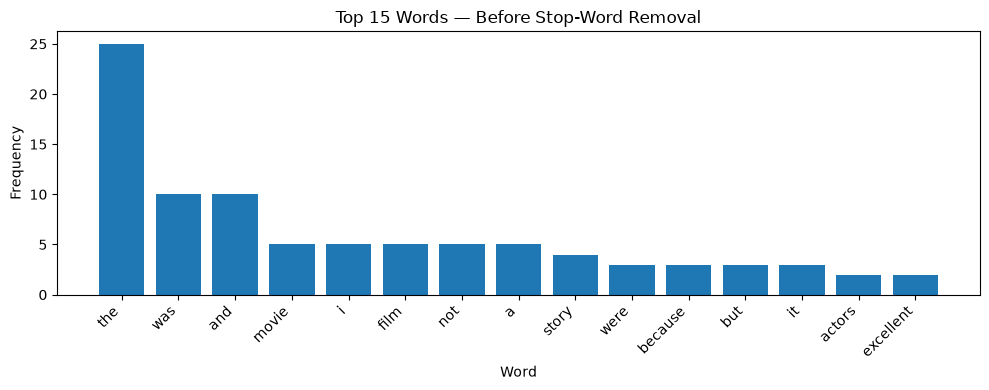

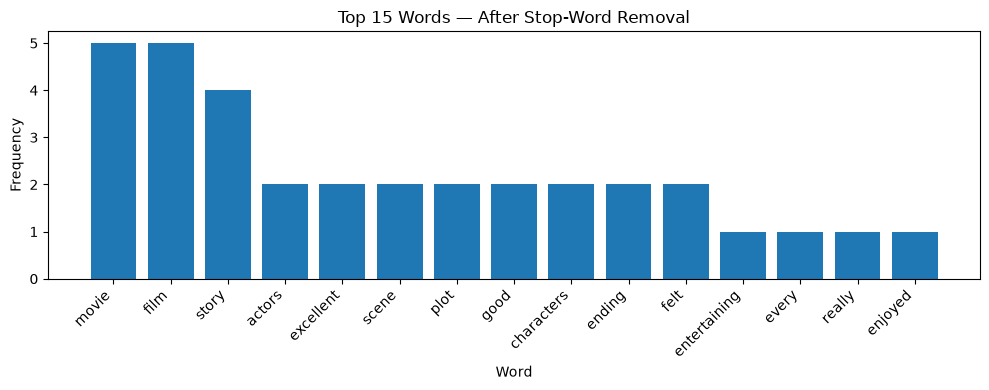

In [10]:
before_counts = Counter(tokens_before).most_common(15)
after_counts = Counter(tokens_after).most_common(15)

def plot_top_words(counts, title):
    words, freqs = zip(*counts)
    plt.figure(figsize=(10, 4))
    plt.bar(words, freqs)
    plt.title(title)
    plt.xlabel("Word")
    plt.ylabel("Frequency")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

plot_top_words(before_counts, "Top 15 Words — Before Stop-Word Removal")
plot_top_words(after_counts, "Top 15 Words — After Stop-Word Removal")


In [11]:
domain_stopwords = {
    "movie": "Very common in a movie-review collection and may add little discrimination.",
    "film": "Domain label that occurs in many reviews regardless of sentiment.",
    "actor": "Generic movie-domain term.",
    "actors": "Plural form of a generic movie-domain term.",
    "scene": "Common structural word in film reviews.",
    "story": "Frequent domain term that may be uninformative in some classification tasks.",
    "plot": "Common review vocabulary shared by many documents.",
    "character": "Generic review term.",
    "characters": "Plural generic review term.",
    "director": "Frequent movie-domain role rather than a sentiment cue."
}

custom_stop_words = stop_words.union(domain_stopwords.keys())
display(pd.DataFrame(
    [(w, r) for w, r in domain_stopwords.items()],
    columns=["Added stop word", "Justification"]
))
print("Custom stop-word set size:", len(custom_stop_words))


,Added stop word,Justification
0,movie,Very common in a movie-review collection and may add little discrimination.
1,film,Domain label that occurs in many reviews regardless of sentiment.
2,actor,Generic movie-domain term.
3,actors,Plural form of a generic movie-domain term.
4,scene,Common structural word in film reviews.
5,story,Frequent domain term that may be uninformative in some classification tasks.
6,plot,Common review vocabulary shared by many documents.
7,character,Generic review term.
8,characters,Plural generic review term.
9,director,Frequent movie-domain role rather than a sentiment cue.


Custom stop-word set size: 208


### Observation

Stop-word removal reduces the number of tokens and usually shortens documents. It also changes the most frequent words from grammatical function words toward content words. Domain-specific stop words can be useful, but they should be validated because a frequent word can still carry task-specific meaning.


# Task 4 — Risks of Stop-Word Removal: Sentiment, MT, and Chatbots

**Goal:** Show why blind stop-word removal can change meaning.

Negation words such as `not`, `no`, and `never` are especially important. Removing them can reverse sentiment, distort translation, and damage chatbot intent.


In [12]:
negation_sentences = [
    "The movie is not good.",
    "I am never happy with this service.",
    "This feature is not helpful.",
    "I do not recommend this product.",
    "The result is not amazing."
]

positive_cues = {"good", "happy", "helpful", "recommend", "amazing"}

def blind_remove_stopwords(text):
    toks = basic_tokens(text)
    return " ".join(t for t in toks if t not in stop_words)

def tiny_negation_sentiment(text):
    toks = basic_tokens(text)
    score = 0
    for i, tok in enumerate(toks):
        if tok in positive_cues:
            previous = toks[max(0, i-2):i]
            score += -1 if any(n in previous for n in {"not", "never", "no"}) else 1
    return "Positive" if score > 0 else ("Negative" if score < 0 else "Neutral")

rows = []
for s in negation_sentences:
    reduced = blind_remove_stopwords(s)
    rows.append([s, reduced, tiny_negation_sentiment(s), tiny_negation_sentiment(reduced)])

display(pd.DataFrame(
    rows,
    columns=["Original", "After blind stop-word removal", "Original sentiment", "After removal"]
))


,Original,After blind stop-word removal,Original sentiment,After removal
0,The movie is not good.,movie good,Negative,Positive
1,I am never happy with this service.,never happy service,Negative,Negative
2,This feature is not helpful.,feature helpful,Negative,Positive
3,I do not recommend this product.,recommend product,Negative,Positive
4,The result is not amazing.,result amazing,Negative,Positive


In [13]:
# Offline, reproducible Urdu examples.
# In an internet-enabled environment, these can be replaced with Google Translate/deep-translator calls.
translation_examples = [
    ("I do not like this service.", "مجھے یہ سروس پسند نہیں ہے۔", "سروس پسند ہے۔"),
    ("She is not coming to class today.", "وہ آج کلاس میں نہیں آ رہی۔", "آج کلاس آنا۔"),
    ("We should not cancel the order.", "ہمیں آرڈر منسوخ نہیں کرنا چاہیے۔", "آرڈر منسوخ کریں۔")
]

translation_rows = []
for original, original_urdu, reduced_urdu in translation_examples:
    reduced = blind_remove_stopwords(original)
    translation_rows.append([original, reduced, original_urdu, reduced_urdu])

display(pd.DataFrame(
    translation_rows,
    columns=["Original English", "Reduced English", "Urdu: original meaning", "Urdu: reduced/distorted meaning"]
))


,Original English,Reduced English,Urdu: original meaning,Urdu: reduced/distorted meaning
0,I do not like this service.,like service,مجھے یہ سروس پسند نہیں ہے۔,سروس پسند ہے۔
1,She is not coming to class today.,coming class today,وہ آج کلاس میں نہیں آ رہی۔,آج کلاس آنا۔
2,We should not cancel the order.,cancel order,ہمیں آرڈر منسوخ نہیں کرنا چاہیے۔,آرڈر منسوخ کریں۔


In [14]:
chatbot_queries = [
    "How can I not be charged again?",
    "What is the status of my order?",
    "Why was my payment not accepted?",
    "Can I cancel the order without a fee?",
    "I do not want to renew my subscription."
]

display(pd.DataFrame({
    "Original query": chatbot_queries,
    "After blind stop-word removal": [blind_remove_stopwords(q) for q in chatbot_queries]
}))


,Original query,After blind stop-word removal
0,How can I not be charged again?,charged
1,What is the status of my order?,status order
2,Why was my payment not accepted?,payment accepted
3,Can I cancel the order without a fee?,cancel order without fee
4,I do not want to renew my subscription.,want renew subscription


In [15]:
protected_words = {"no", "not", "never", "nor", "without"}
safe_stop_words = stop_words - protected_words

def safe_remove_stopwords(text):
    toks = basic_tokens(text)
    return " ".join(t for t in toks if t not in safe_stop_words)

safe_rows = []
for s in negation_sentences:
    reduced = safe_remove_stopwords(s)
    safe_rows.append([s, reduced, tiny_negation_sentiment(reduced)])

display(pd.DataFrame(
    safe_rows,
    columns=["Original", "After safe stop-word removal", "Sentiment after safe removal"]
))


,Original,After safe stop-word removal,Sentiment after safe removal
0,The movie is not good.,movie not good,Negative
1,I am never happy with this service.,never happy service,Negative
2,This feature is not helpful.,feature not helpful,Negative
3,I do not recommend this product.,not recommend product,Negative
4,The result is not amazing.,result not amazing,Negative


### Safe Stop-Word Strategy

A safer approach preserves **negation and other intent-bearing function words**. For sentiment, words such as `not`, `no`, and `never` are critical. For chatbots, `without`, question words, and modality can also matter. For machine translation, aggressive stop-word removal is usually inappropriate because grammatical words help determine the complete meaning.


# Task 5 — Hands-On with the Porter Stemmer

**Goal:** Study stemming behavior, identify over-stemming and under-stemming, and compare Porter with Snowball.

A **stem** is a mechanically reduced form and does not have to be a valid dictionary word.


In [16]:
porter = PorterStemmer()
snowball = SnowballStemmer("english")

word_expected = {
    "running":"run", "runs":"run", "runner":"runner", "studies":"study", "studying":"study",
    "happily":"happy", "happiness":"happy", "generalization":"generalize", "generalized":"generalize",
    "better":"good", "best":"good", "was":"be", "were":"be", "cars":"car", "boxes":"box",
    "flies":"fly", "flying":"fly", "relational":"relate", "conditional":"condition",
    "organization":"organization", "organ":"organ", "university":"university", "universe":"universe",
    "generous":"generous", "generation":"generation", "connected":"connect", "connecting":"connect",
    "connection":"connection", "easily":"easy", "fairness":"fair", "arguing":"argue",
    "argued":"argue", "nationalization":"nationalize", "ponies":"pony", "caresses":"caress",
    "children":"child", "went":"go"
}

rows = []
for word, expected in word_expected.items():
    stem = porter.stem(word)
    rows.append([word, stem, expected, "Correct" if stem == expected else "Incorrect"])

display(pd.DataFrame(rows, columns=["Word", "Porter Stem", "Expected base/lemma", "Correct/Incorrect"]))


,Word,Porter Stem,Expected base/lemma,Correct/Incorrect
0,running,run,run,Correct
1,runs,run,run,Correct
2,runner,runner,runner,Correct
3,studies,studi,study,Incorrect
4,studying,studi,study,Incorrect
5,happily,happili,happy,Incorrect
6,happiness,happi,happy,Incorrect
7,generalization,gener,generalize,Incorrect
8,generalized,gener,generalize,Incorrect
9,better,better,good,Incorrect


In [17]:
over_pairs = [
    ("university", "universe"),
    ("organization", "organ"),
    ("generous", "generation")
]
under_pairs = [
    ("good", "better"),
    ("go", "went"),
    ("be", "was"),
    ("child", "children")
]

print("Over-stemming: different meanings collapse to the same stem")
display(pd.DataFrame(
    [[a, b, porter.stem(a), porter.stem(b)] for a, b in over_pairs],
    columns=["Word 1", "Word 2", "Stem 1", "Stem 2"]
))

print("Under-stemming: related forms remain as different stems")
display(pd.DataFrame(
    [[a, b, porter.stem(a), porter.stem(b)] for a, b in under_pairs],
    columns=["Related Word 1", "Related Word 2", "Stem 1", "Stem 2"]
))


Over-stemming: different meanings collapse to the same stem


,Word 1,Word 2,Stem 1,Stem 2
0,university,universe,univers,univers
1,organization,organ,organ,organ
2,generous,generation,gener,gener


Under-stemming: related forms remain as different stems


,Related Word 1,Related Word 2,Stem 1,Stem 2
0,good,better,good,better
1,go,went,go,went
2,be,was,be,wa
3,child,children,child,children


In [18]:
comparison = pd.DataFrame({
    "Word": list(word_expected.keys()),
    "Porter": [porter.stem(w) for w in word_expected],
    "Snowball": [snowball.stem(w) for w in word_expected]
})
comparison["Different?"] = comparison["Porter"] != comparison["Snowball"]
display(comparison)
print("Number of words with different outputs:", int(comparison["Different?"].sum()))


,Word,Porter,Snowball,Different?
0,running,run,run,False
1,runs,run,run,False
2,runner,runner,runner,False
3,studies,studi,studi,False
4,studying,studi,studi,False
5,happily,happili,happili,False
6,happiness,happi,happi,False
7,generalization,gener,general,True
8,generalized,gener,general,True
9,better,better,better,False


Number of words with different outputs: 5


### Observation

Porter stemming is fast and useful for reducing morphological variation, but its output is not guaranteed to be a real word. **Over-stemming** merges unrelated words, while **under-stemming** fails to merge related irregular forms. Snowball is a later rule-based stemmer and can produce different results for some words.


# Task 6 — Lemmatization (spaCy) vs. Stemming

**Goal:** Compare stem and lemma side by side and study the importance of part-of-speech (POS) information.

The code attempts to load spaCy's `en_core_web_sm`. If it is not installed, it uses spaCy's English tokenizer plus a small offline rule-based fallback for lemma/POS values so that the notebook remains fully executable.


In [19]:
paragraph = """
Yesterday the students were studying natural language processing in the university laboratory.
They were running several experiments and comparing better methods for cleaning noisy documents.
One group studies customer reviews, while another group analyzes messages written by users.
The researchers found that children sometimes use shorter expressions and that people went directly
to the important words when they were searching. A good preprocessing system keeps useful meaning
while removing unnecessary noise. The students also learned that stemming can produce strange forms,
whereas careful lemmatization often returns proper dictionary words. Their instructor was explaining
why part of speech matters: the word better can be related to good, and the word was can be related to be.
After the experiments, everyone discussed the results, compared models, and wrote conclusions about
accuracy, speed, vocabulary size, and the risks of applying the same preprocessing rules to every task.
"""
print("Paragraph word count:", len(re.findall(r"\b\w+\b", paragraph)))


Paragraph word count: 144


In [20]:
import spacy

IRREGULAR_LEMMAS = {
    "better":"good", "best":"good", "was":"be", "were":"be", "is":"be", "are":"be", "am":"be",
    "went":"go", "gone":"go", "children":"child", "mice":"mouse", "studies":"study",
    "studying":"study", "running":"run", "written":"write", "found":"find", "keeps":"keep",
    "learned":"learn", "students":"student", "researchers":"researcher", "experiments":"experiment",
    "methods":"method", "documents":"document", "messages":"message", "users":"user",
    "words":"word", "results":"result", "models":"model", "conclusions":"conclusion", "rules":"rule"
}

def simple_lemma(word):
    w = word.lower()
    if w in IRREGULAR_LEMMAS:
        return IRREGULAR_LEMMAS[w]
    if len(w) > 5 and w.endswith("ing"):
        base = w[:-3]
        if len(base) >= 2 and base[-1] == base[-2]:
            base = base[:-1]
        return base
    if len(w) > 4 and w.endswith("ed"):
        base = w[:-2]
        if len(base) >= 2 and base[-1] == base[-2]:
            base = base[:-1]
        return base
    if len(w) > 4 and w.endswith("ies"):
        return w[:-3] + "y"
    if len(w) > 3 and w.endswith("s") and not w.endswith("ss"):
        return w[:-1]
    return w

def simple_pos(word):
    w = word.lower()
    if w in {"was","were","is","are","am","be","been","went","found","keeps","learned","studying",
             "running","written","removing","applying","discussed","compared","wrote","searching","explaining"}:
        return "VERB"
    if w in {"better","good","useful","noisy","important","unnecessary","strange","careful","proper","same"}:
        return "ADJ"
    if w.endswith("ly"):
        return "ADV"
    if re.fullmatch(r"[A-Za-z]+", word):
        return "NOUN"
    return "PUNCT"

try:
    nlp = spacy.load("en_core_web_sm")
    SPACY_MODE = "en_core_web_sm"
except OSError:
    nlp = spacy.blank("en")
    SPACY_MODE = "spaCy tokenizer + offline rule-based lemma/POS fallback"

doc = nlp(paragraph)
print("Mode used:", SPACY_MODE)


Mode used: spaCy tokenizer + offline rule-based lemma/POS fallback


In [21]:
comparison_rows = []
for tok in doc:
    if not tok.is_alpha:
        continue
    if SPACY_MODE == "en_core_web_sm":
        lemma = tok.lemma_
        pos = tok.pos_
    else:
        lemma = simple_lemma(tok.text)
        pos = simple_pos(tok.text)
    comparison_rows.append([tok.text, pos, porter.stem(tok.text.lower()), lemma])

lemma_compare_df = pd.DataFrame(
    comparison_rows,
    columns=["Token", "POS", "Porter Stem", "Lemma"]
)
display(lemma_compare_df)


,Token,POS,Porter Stem,Lemma
0,Yesterday,NOUN,yesterday,yesterday
1,the,NOUN,the,the
2,students,NOUN,student,student
3,were,VERB,were,be
4,studying,VERB,studi,study
5,natural,NOUN,natur,natural
6,language,NOUN,languag,language
7,processing,NOUN,process,proces
8,in,NOUN,in,in
9,the,NOUN,the,the


In [22]:
focus_words = {"better", "was", "children", "went", "studies", "running"}
focus_df = lemma_compare_df[
    lemma_compare_df["Token"].str.lower().isin(focus_words)
].drop_duplicates(subset=["Token"])
display(focus_df)


,Token,POS,Porter Stem,Lemma
14,running,VERB,run,run
19,better,ADJ,better,good
27,studies,NOUN,studi,study
42,children,NOUN,children,child
50,went,VERB,went,go
91,was,VERB,wa,be


### Why POS Helps Lemmatization

Lemmatization tries to return a **dictionary base form**, while stemming mainly removes character suffixes. POS information helps identify how a word functions in context. For example, the adjective `better` can be normalized to `good`, and the verb `was` can be normalized to `be`. A mechanical stemmer cannot reliably infer these irregular relationships.


In [23]:
tokens_for_speed = [t.lower() for t in re.findall(r"\b[A-Za-z]+\b", paragraph)] * 200

start = time.perf_counter()
_ = [porter.stem(t) for t in tokens_for_speed]
porter_time = time.perf_counter() - start

start = time.perf_counter()
if SPACY_MODE == "en_core_web_sm":
    _ = list(nlp(" ".join(tokens_for_speed[:5000])))
else:
    _ = [simple_lemma(t) for t in tokens_for_speed]
lemma_time = time.perf_counter() - start

display(pd.DataFrame({
    "Method": ["Porter stemming", "Lemmatization"],
    "Time (seconds)": [porter_time, lemma_time]
}))
print("Use stemming when speed and rough normalization matter most.")
print("Use lemmatization when readable linguistic base forms and context are more important.")


,Method,Time (seconds)
0,Porter stemming,2.085825
1,Lemmatization,0.088321


Use stemming when speed and rough normalization matter most.
Use lemmatization when readable linguistic base forms and context are more important.


# Task 7 — Configurable Preprocessing Pipeline

**Goal:** Combine the techniques into one pipeline, compare four configurations on at least 50 documents, and run a small TF-IDF + Logistic Regression classification experiment.


In [24]:
positive_openers = [
    "I loved this movie", "This film was excellent", "What a wonderful story",
    "The movie was enjoyable", "I really liked this film", "This was a great experience"
]
positive_details = [
    "the acting was strong and the ending was satisfying",
    "the characters were interesting and the story was engaging",
    "the direction was smart and the music was beautiful",
    "the performances were convincing and the plot was entertaining",
    "the scenes were memorable and the pace felt right"
]
negative_openers = [
    "I hated this movie", "This film was terrible", "What a disappointing story",
    "The movie was boring", "I really disliked this film", "This was a poor experience"
]
negative_details = [
    "the acting was weak and the ending was frustrating",
    "the characters were dull and the story was confusing",
    "the direction was messy and the music was annoying",
    "the performances were unconvincing and the plot was predictable",
    "the scenes were forgettable and the pace felt slow"
]

documents, labels = [], []
for opener in positive_openers:
    for detail in positive_details:
        documents.append(f"{opener}; {detail}.")
        labels.append("positive")
for opener in negative_openers:
    for detail in negative_details:
        documents.append(f"{opener}; {detail}.")
        labels.append("negative")

print("Documents:", len(documents))
print("Class counts:", Counter(labels))


Documents: 60
Class counts: Counter({'positive': 30, 'negative': 30})


In [25]:
def pipeline_process(text, lowercase=True, noise_removal=False, remove_stops=False, method=None):
    if lowercase:
        text = text.lower()
    if noise_removal:
        text = clean_text(text)
    tokens = re.findall(r"\b[a-zA-Z']+\b", text)
    if remove_stops:
        tokens = [t for t in tokens if t not in stop_words]
    if method == "stem":
        tokens = [porter.stem(t) for t in tokens]
    elif method == "lemma":
        tokens = [simple_lemma(t) for t in tokens]
    return tokens

configs = {
    "Lowercase only": dict(lowercase=True, remove_stops=False, method=None),
    "Lowercase + stop-words": dict(lowercase=True, remove_stops=True, method=None),
    "Lowercase + stemming": dict(lowercase=True, remove_stops=False, method="stem"),
    "Lowercase + lemmatization": dict(lowercase=True, remove_stops=False, method="lemma")
}

processed_by_config = {
    name: [pipeline_process(doc, **cfg) for doc in documents]
    for name, cfg in configs.items()
}


In [26]:
pipeline_metrics = []
for name, processed_docs in processed_by_config.items():
    all_toks = [t for doc in processed_docs for t in doc]
    pipeline_metrics.append([
        name,
        len(set(all_toks)),
        np.mean([len(doc) for doc in processed_docs])
    ])

display(pd.DataFrame(
    pipeline_metrics,
    columns=["Configuration", "Vocabulary size", "Average tokens/document"]
).round(2))


,Configuration,Vocabulary size,Average tokens/document
0,Lowercase only,55,13.33
1,Lowercase + stop-words,47,6.37
2,Lowercase + stemming,55,13.33
3,Lowercase + lemmatization,54,13.33


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

indices = np.arange(len(documents))
train_idx, test_idx = train_test_split(
    indices, test_size=0.30, random_state=42, stratify=labels
)

classification_rows = []
for name, processed_docs in processed_by_config.items():
    texts = [" ".join(tokens) for tokens in processed_docs]
    X_train_text = [texts[i] for i in train_idx]
    X_test_text = [texts[i] for i in test_idx]
    y_train = [labels[i] for i in train_idx]
    y_test = [labels[i] for i in test_idx]

    vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
    X_train = vectorizer.fit_transform(X_train_text)
    X_test = vectorizer.transform(X_test_text)

    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    classification_rows.append([
        name, len(vectorizer.vocabulary_), accuracy_score(y_test, pred)
    ])

results_df = pd.DataFrame(
    classification_rows,
    columns=["Configuration", "TF-IDF features", "Accuracy"]
).sort_values("Accuracy", ascending=False)

display(results_df)


,Configuration,TF-IDF features,Accuracy
0,Lowercase only,55,1.0
1,Lowercase + stop-words,47,1.0
2,Lowercase + stemming,55,1.0
3,Lowercase + lemmatization,54,1.0


In [28]:
best_accuracy = results_df["Accuracy"].max()
best_names = results_df.loc[results_df["Accuracy"] == best_accuracy, "Configuration"].tolist()

print("Analysis:")
print(f"1. The highest observed test accuracy was {best_accuracy:.3f}, achieved by: {', '.join(best_names)}.")
print("2. Lowercasing reduces case-based duplication and gives a consistent representation.")
print("3. Stop-word removal reduces average document length, but it can also remove useful context.")
print("4. Stemming reduces morphological variation but may create non-dictionary forms.")
print("5. Lemmatization aims for cleaner base forms and is easier for humans to interpret.")
print("6. The best preprocessing choice depends on the dataset; this experiment is not a universal ranking.")


Analysis:
1. The highest observed test accuracy was 1.000, achieved by: Lowercase only, Lowercase + stop-words, Lowercase + stemming, Lowercase + lemmatization.
2. Lowercasing reduces case-based duplication and gives a consistent representation.
3. Stop-word removal reduces average document length, but it can also remove useful context.
4. Stemming reduces morphological variation but may create non-dictionary forms.
5. Lemmatization aims for cleaner base forms and is easier for humans to interpret.
6. The best preprocessing choice depends on the dataset; this experiment is not a universal ranking.


# Task 8 — Minimum Edit Distance (Levenshtein)

**Goal:** Implement recursive and dynamic-programming edit distance, print DP tables, backtrace edit operations, and compare substitution costs of 1 and 2.


In [29]:
def levenshtein_recursive(a, b):
    if len(a) == 0:
        return len(b)
    if len(b) == 0:
        return len(a)

    sub_cost = 0 if a[-1] == b[-1] else 1
    return min(
        levenshtein_recursive(a[:-1], b) + 1,
        levenshtein_recursive(a, b[:-1]) + 1,
        levenshtein_recursive(a[:-1], b[:-1]) + sub_cost
    )

print("Recursive distance between 'cat' and 'cut':", levenshtein_recursive("cat", "cut"))


Recursive distance between 'cat' and 'cut': 1


### Limitation of the Recursive Version

Without memoization, the recursive function repeatedly solves the same subproblems. Its time grows exponentially, so it becomes impractical for longer strings. Dynamic programming stores intermediate results and reduces the computation to approximately **O(m × n)** time for strings of lengths `m` and `n`.


In [30]:
def levenshtein_dp(a, b, substitution_cost=1):
    m, n = len(a), len(b)
    dp = np.zeros((m + 1, n + 1), dtype=int)
    dp[:, 0] = np.arange(m + 1)
    dp[0, :] = np.arange(n + 1)

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if a[i-1] == b[j-1] else substitution_cost
            dp[i, j] = min(
                dp[i-1, j] + 1,
                dp[i, j-1] + 1,
                dp[i-1, j-1] + cost
            )
    return dp[m, n], dp

def dp_dataframe(a, b, dp):
    return pd.DataFrame(dp, index=["∅"] + list(a), columns=["∅"] + list(b))

for a, b in [("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday")]:
    dist, table = levenshtein_dp(a, b, substitution_cost=1)
    print(f"\n{a!r} -> {b!r} | distance = {dist}")
    display(dp_dataframe(a, b, table))



'intention' -> 'execution' | distance = 5


,∅,e,x,e,c,u,t,i,o,n
∅,0,1,2,3,4,5,6,7,8,9
i,1,1,2,3,4,5,6,6,7,8
n,2,2,2,3,4,5,6,7,7,7
t,3,3,3,3,4,5,5,6,7,8
e,4,3,4,3,4,5,6,6,7,8
n,5,4,4,4,4,5,6,7,7,7
t,6,5,5,5,5,5,5,6,7,8
i,7,6,6,6,6,6,6,5,6,7
o,8,7,7,7,7,7,7,6,5,6
n,9,8,8,8,8,8,8,7,6,5



'kitten' -> 'sitting' | distance = 3


,∅,s,i,t,t,i,n,g
∅,0,1,2,3,4,5,6,7
k,1,1,2,3,4,5,6,7
i,2,2,1,2,3,4,5,6
t,3,3,2,1,2,3,4,5
t,4,4,3,2,1,2,3,4
e,5,5,4,3,2,2,3,4
n,6,6,5,4,3,3,2,3



'sunday' -> 'saturday' | distance = 3


,∅,s,a,t,u,r,d,a,y
∅,0,1,2,3,4,5,6,7,8
s,1,0,1,2,3,4,5,6,7
u,2,1,1,2,2,3,4,5,6
n,3,2,2,2,3,3,4,5,6
d,4,3,3,3,3,4,3,4,5
a,5,4,3,4,4,4,4,3,4
y,6,5,4,4,5,5,5,4,3


### Hand-Construction Rule for the DP Table

To reproduce each table by hand:

1. Write the first string vertically and the second horizontally.
2. Fill the top row and first column with `0, 1, 2, ...`.
3. For each cell, take the minimum of:
   - **top + 1** for deletion,
   - **left + 1** for insertion,
   - **diagonal + 0** if characters match, otherwise **diagonal + substitution cost**.
4. The bottom-right cell is the minimum edit distance.

The printed matrices above are complete DP tables and can be copied into a handwritten solution.


In [31]:
def levenshtein_with_backtrace(a, b, substitution_cost=1):
    distance, dp = levenshtein_dp(a, b, substitution_cost=substitution_cost)
    i, j = len(a), len(b)
    operations = []

    while i > 0 or j > 0:
        if i > 0 and j > 0 and a[i-1] == b[j-1] and dp[i, j] == dp[i-1, j-1]:
            operations.append(("MATCH", a[i-1], b[j-1]))
            i -= 1; j -= 1
            continue

        if i > 0 and j > 0:
            sub = 0 if a[i-1] == b[j-1] else substitution_cost
            if dp[i, j] == dp[i-1, j-1] + sub:
                operations.append(("SUBSTITUTE", a[i-1], b[j-1]))
                i -= 1; j -= 1
                continue

        if i > 0 and dp[i, j] == dp[i-1, j] + 1:
            operations.append(("DELETE", a[i-1], "∅"))
            i -= 1
            continue

        if j > 0 and dp[i, j] == dp[i, j-1] + 1:
            operations.append(("INSERT", "∅", b[j-1]))
            j -= 1
            continue

    operations.reverse()
    return distance, operations

for sub_cost in [1, 2]:
    dist, ops = levenshtein_with_backtrace("intention", "execution", substitution_cost=sub_cost)
    print(f"\nSubstitution cost = {sub_cost}; distance = {dist}")
    display(pd.DataFrame(ops, columns=["Operation", "From", "To"]))

comparison_costs = []
for a, b in [("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday")]:
    d1, _ = levenshtein_dp(a, b, substitution_cost=1)
    d2, _ = levenshtein_dp(a, b, substitution_cost=2)
    comparison_costs.append([a, b, d1, d2])

display(pd.DataFrame(
    comparison_costs,
    columns=["String 1", "String 2", "Distance (sub=1)", "Distance (sub=2)"]
))



Substitution cost = 1; distance = 5


,Operation,From,To
0,SUBSTITUTE,i,e
1,SUBSTITUTE,n,x
2,SUBSTITUTE,t,e
3,SUBSTITUTE,e,c
4,SUBSTITUTE,n,u
5,MATCH,t,t
6,MATCH,i,i
7,MATCH,o,o
8,MATCH,n,n



Substitution cost = 2; distance = 8


,Operation,From,To
0,DELETE,i,∅
1,SUBSTITUTE,n,e
2,SUBSTITUTE,t,x
3,MATCH,e,e
4,INSERT,∅,c
5,SUBSTITUTE,n,u
6,MATCH,t,t
7,MATCH,i,i
8,MATCH,o,o
9,MATCH,n,n


,String 1,String 2,Distance (sub=1),Distance (sub=2)
0,intention,execution,5,8
1,kitten,sitting,3,5
2,sunday,saturday,3,4


# Task 9 — Spelling Correction with Edit Distance

**Goal:** Use a vocabulary of at least 5,000 words, suggest nearest candidates, calculate Top-1 accuracy, and improve tie-breaking with word frequency.

`textblob.en.spelling` provides a local word-frequency dictionary, allowing the notebook to run without downloading a corpus.


In [32]:
from textblob.en import spelling

test_pairs = {
    "recieve":"receive",
    "definately":"definitely",
    "acommodate":"accommodate",
    "seperate":"separate",
    "occured":"occurred",
    "goverment":"government",
    "enviroment":"environment",
    "becuase":"because",
    "wierd":"weird",
    "adress":"address",
    "teir":"their",
    "woudl":"would",
    "coud":"could",
    "shuold":"should",
    "tese":"these"
}

ranked_words = [
    w for w, freq in sorted(spelling.items(), key=lambda kv: kv[1], reverse=True)
    if re.fullmatch(r"[a-z]+", w)
]
vocabulary = set(ranked_words[:7000]) | set(test_pairs.values())
vocabulary = sorted(vocabulary)

print("Vocabulary size:", len(vocabulary))
print("Underlying TextBlob spelling dictionary size:", len(spelling))


Vocabulary size: 7003
Underlying TextBlob spelling dictionary size: 29157


In [33]:
def edit_distance_fast(a, b):
    if len(a) < len(b):
        a, b = b, a
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j-1] + (ca != cb)
            ))
        previous = current
    return previous[-1]

def suggest(word, k=5):
    scored = [(edit_distance_fast(word, candidate), candidate) for candidate in vocabulary]
    scored.sort(key=lambda x: (x[0], x[1]))
    return [candidate for _, candidate in scored[:k]]

def suggest_with_frequency(word, k=5):
    scored = [
        (edit_distance_fast(word, candidate), -spelling.get(candidate, 0), candidate)
        for candidate in vocabulary
    ]
    scored.sort()
    return [candidate for _, _, candidate in scored[:k]]

print("Example suggestions for 'recieve':")
print("Baseline:", suggest("recieve", 5))
print("Frequency-aware:", suggest_with_frequency("recieve", 5))


Example suggestions for 'recieve':


Baseline: ['relieve', 'believe', 'receive', 'relieved', 'believed']


Frequency-aware: ['relieve', 'believe', 'receive', 'relieved', 'received']


In [34]:
spell_rows = []
for misspelled, correct in test_pairs.items():
    base_top5 = suggest(misspelled, 5)
    freq_top5 = suggest_with_frequency(misspelled, 5)
    spell_rows.append([
        misspelled, correct, base_top5[0], freq_top5[0],
        correct in base_top5, correct in freq_top5,
        base_top5, freq_top5
    ])

spell_df = pd.DataFrame(spell_rows, columns=[
    "Misspelled", "Gold correction", "Baseline Top-1", "Frequency Top-1",
    "Baseline Top-5 contains gold?", "Frequency Top-5 contains gold?",
    "Baseline Top-5", "Frequency Top-5"
])
display(spell_df)

baseline_acc = (spell_df["Baseline Top-1"] == spell_df["Gold correction"]).mean()
frequency_acc = (spell_df["Frequency Top-1"] == spell_df["Gold correction"]).mean()

print(f"Baseline Top-1 accuracy:        {baseline_acc:.2%}")
print(f"Frequency-aware Top-1 accuracy: {frequency_acc:.2%}")


,Misspelled,Gold correction,Baseline Top-1,Frequency Top-1,Baseline Top-5 contains gold?,Frequency Top-5 contains gold?,Baseline Top-5,Frequency Top-5
0,recieve,receive,relieve,relieve,True,True,"[relieve, believe, receive, relieved, believed]","[relieve, believe, receive, relieved, received]"
1,definately,definitely,definitely,definitely,True,True,"[definitely, definite, infinitely, dedicated, defeated]","[definitely, definite, infinitely, finally, defined]"
2,acommodate,accommodate,accommodate,accommodate,True,True,"[accommodate, accumulated, accurate, advocate, candidate]","[accommodate, common, command, complete, commerce]"
3,seperate,separate,separate,separate,True,True,"[separate, desperate, operate, separated, separates]","[separate, separated, desperate, operate, separates]"
4,occured,occurred,occurred,occurred,True,True,"[occurred, accused, occupied, occur, occurs]","[occurred, occur, occurs, occupied, secured]"
5,goverment,government,government,government,True,True,"[government, governments, movement, govern, governed]","[government, movement, governments, movements, governed]"
6,enviroment,environment,environment,environment,True,True,"[environment, enforcement, engagement, enjoyment, enlargement]","[environment, government, evident, excitement, enlargement]"
7,becuase,because,became,because,True,True,"[became, because, base, beast, beausset]","[because, became, case, become, secure]"
8,wierd,weird,bier,were,False,False,"[bier, bird, died, field, herd]","[were, where, word, field, died]"
9,adress,address,address,dress,True,True,"[address, dress, access, acres, across]","[dress, address, across, press, arrest]"


Baseline Top-1 accuracy:        46.67%
Frequency-aware Top-1 accuracy: 80.00%


In [35]:
display(pd.DataFrame([
    ["their house is large", "there house is large", "Both 'their' and 'there' are valid dictionary words."],
    ["I want two books", "I want to books", "Both 'two' and 'to' are valid dictionary words."],
    ["The weather is nice", "The whether is nice", "Both forms can exist as real words."]
], columns=["Intended", "Real-word error", "Why edit-distance correction struggles"]))


,Intended,Real-word error,Why edit-distance correction struggles
0,their house is large,there house is large,Both 'their' and 'there' are valid dictionary words.
1,I want two books,I want to books,Both 'two' and 'to' are valid dictionary words.
2,The weather is nice,The whether is nice,Both forms can exist as real words.


### Observations on Spelling Correction

1. Edit distance is effective for **non-word errors** because a misspelled token can be compared with nearby dictionary candidates.
2. Several candidates may have the same minimum distance, so the ranking rule matters.
3. **Word frequency as a tie-breaker** can place a common intended word above a less likely candidate.
4. Accuracy still depends on the vocabulary: if the correct word is missing, it cannot be suggested.
5. Pure edit distance does not understand sentence context.
6. Therefore, **real-word errors** such as `their/there` are difficult because both tokens are valid dictionary entries.


# Final Conclusion

This lab shows that preprocessing is not simply “cleaning everything.” Lowercasing, regex cleaning, stop-word removal, stemming, and lemmatization each trade information for normalization. The safest pipeline depends on the downstream task. Minimum edit distance provides a clear dynamic-programming solution for string similarity and supports spelling correction, while frequency information improves candidate ranking. Context remains essential for ambiguous words, negation, named entities, translation, and real-word spelling errors.
